# HW2 Part 1: Data cleaning

This notebook cleans `ohlc_hw` and saves the result as `ohlc_hw_cleaned` in my local copy `data/data.db`. `ohlc_hw` itself is only read.

It also saves `ohlc_hw_quarantine` (rows I couldn't repair, with the reason), `ohlc_hw_ticker_audit` (raw ticker label to clean ticker) and `ohlc_hw_quality_report` (the issues found before cleaning).

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB_PATH = Path('data/data.db')
PRICE_COLS = ['open', 'high', 'low', 'close']
KEY = ['ticker', 'ts']
VALUE_COLS = ['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume']

## 1.1 Load and inspect

I also load `ohlc`, the reference table from the course. I only use it as a trading calendar for each ticker and to look up adjustment factors, not to replace rows of `ohlc_hw`.

In [2]:
with closing(sqlite3.connect(DB_PATH)) as conn:
    raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)
    reference = pd.read_sql_query('SELECT ticker, ts, close, adj_close FROM ohlc', conn)
RAW_ROWS = len(raw)

raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  str    
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  str    
dtypes: float64(5), int64(1), str(2)
memory usage: 31.6 MB


In [3]:
display(raw.describe())
display(raw.head())

,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


,ts,open,high,low,close,adj_close,volume,ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL


| column | meaning |
|---|---|
| `ts` | trading date (text, `YYYY-MM-DD`) |
| `ticker` | stock symbol as sent by the vendor |
| `open`, `high`, `low`, `close` | raw daily prices |
| `adj_close` | close adjusted for splits and dividends, used for returns |
| `volume` | shares traded |

In [4]:
print(f'{RAW_ROWS:,} rows, dates {raw["ts"].min()} to {raw["ts"].max()}')
print(f'{raw["ticker"].nunique()} distinct raw ticker labels, for example:')
display(raw['ticker'].drop_duplicates().sample(5, random_state=1).to_frame('raw label'))

397,711 rows, dates 1962-01-02 to 2024-12-06
150 distinct raw ticker labels, for example:


,raw label
20,HON
965,"<a target=""_blank""><span style=""font-weight: b..."
568,"<a target=""_blank""><span style=""color: blue"">C..."
23,MMM
2166,"<a target=""_blank""><span style=""font-weight: b..."


Some tickers come wrapped in HTML (like `<span style="color: red">KO</span>`), so there are 150 labels for 30 stocks. This has to be fixed before any groupby or duplicate check. I keep the original label in `raw_ticker`.

In [5]:
def normalize_ticker(labels):
    """Remove HTML tags and spaces, upper-case."""
    return labels.str.replace(r'<[^>]+>', '', regex=True).str.strip().str.upper()


def prepare(frame):
    """Clean the tickers (original label kept in raw_ticker) and sort by ticker and date."""
    data = frame.rename(columns={'ticker': 'raw_ticker'})
    data['ticker'] = normalize_ticker(data['raw_ticker'])
    return data.sort_values(KEY, kind='stable').reset_index(drop=True)


data = prepare(raw)
ticker_audit = data.groupby(['ticker', 'raw_ticker']).size().rename('rows').reset_index()
print(f'{ticker_audit["raw_ticker"].nunique()} raw labels -> {data["ticker"].nunique()} tickers')
display(ticker_audit[ticker_audit['ticker'] == 'AAPL'])

bad_dates = pd.to_datetime(data['ts'], format='%Y-%m-%d', errors='coerce').isna().sum()
print('dates not in YYYY-MM-DD format:', bad_dates)

coverage = data.groupby('ticker')['ts'].agg(first_date='min', last_date='max', rows_incl_duplicates='size')
display(coverage)

150 raw labels -> 30 tickers


,ticker,raw_ticker,rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264
4,AAPL,AAPL,10747


dates not in YYYY-MM-DD format: 0


,first_date,last_date,rows_incl_duplicates
ticker,,,
AAPL,1980-12-12,2024-10-18,11942
AMGN,1983-06-17,2024-10-18,11290
AMZN,1997-05-15,2024-12-06,7458
AXP,1972-04-03,2024-10-18,14260
BA,1962-01-02,2024-10-18,16980
CAT,1962-01-02,2024-10-18,17044
CRM,2004-06-23,2024-10-18,5525
CSCO,1990-02-16,2024-10-18,9427
CVX,1962-01-02,2024-12-06,17073


## 1.2 Detect data quality issues

### Duplicates

In [6]:
exact_dup = data.duplicated(VALUE_COLS)
deduped = data[~exact_dup]
conflicts = deduped.duplicated(KEY, keep=False)
print(f'exact duplicate rows: {exact_dup.sum():,}')
print(f'rows sharing a (ticker, ts) with different values: {conflicts.sum()}')

exact duplicate rows: 29,460
rows sharing a (ticker, ts) with different values: 0


### Missing data

Missing cells and missing trading days are two separate checks. A day that was never delivered doesn't show up as a NaN.

In [7]:
display(deduped[PRICE_COLS + ['adj_close', 'volume']].isna().sum().to_frame('missing cells'))

,missing cells
open,0
high,0
low,0
close,0
adj_close,18374
volume,0


For the expected trading days I use each ticker's dates in `ohlc`, from its first to its last date there (plain weekdays would count holidays as gaps). Missing days are only reported, I don't make up prices for them.

In [8]:
def missing_trading_days(frame, calendar):
    """Calendar dates with no row in frame: a per-ticker summary and one row per missing date."""
    observed = frame.groupby('ticker')['ts'].apply(set)
    summary, gaps = [], []
    for ticker, expected in calendar.groupby('ticker')['ts']:
        missing = sorted(set(expected) - observed.get(ticker, set()))
        summary.append({'ticker': ticker, 'start': expected.min(), 'end': expected.max(), 'missing_days': len(missing)})
        gaps.append(pd.DataFrame({'ticker': ticker, 'ts': missing}))
    return pd.DataFrame(summary), pd.concat(gaps, ignore_index=True)


# quick test: 4-day calendar with one date removed from the data
tiny_calendar = pd.DataFrame({'ticker': 'DEMO', 'ts': ['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05']})
tiny_summary, tiny_gaps = missing_trading_days(tiny_calendar.drop(index=1), tiny_calendar)
for row in tiny_summary.itertuples():
    print(f'Ticker {row.ticker} is missing {row.missing_days} trading days between {row.start} and {row.end}')
assert tiny_gaps['ts'].tolist() == ['2024-01-03']

Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-01-05


In [9]:
gap_summary, missing_days = missing_trading_days(deduped, reference[KEY])
for row in gap_summary.itertuples():
    print(f'Ticker {row.ticker} is missing {row.missing_days} trading days between {row.start} and {row.end}')

not_in_calendar = ~deduped.set_index(KEY).index.isin(reference.set_index(KEY).index)
print(f'\ntotal missing trading days: {len(missing_days)}, delivered days not in the calendar: {not_in_calendar.sum()}')

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticke

Since `ohlc` has exactly the same dates as `ohlc_hw`, this can't catch a date that is wrong in both. Checking the day of the week can:

In [10]:
dates = pd.to_datetime(deduped['ts'])
weekend = deduped[dates.dt.day_of_week >= 5]
print(f'rows dated on a weekend: {len(weekend)}', dates[weekend.index].dt.day_name().value_counts().to_dict())
print(f'{weekend["ticker"].nunique()} tickers, {weekend["ts"].nunique()} dates, years {sorted(weekend["ts"].str[:4].unique())}')

# is the Friday before also in the data for the same ticker?
weekend_dates = dates[weekend.index]
friday = (weekend_dates - pd.to_timedelta(weekend_dates.dt.day_of_week - 4, unit='D')).dt.strftime('%Y-%m-%d')
have = set(zip(deduped['ticker'], deduped['ts']))
print('weekend rows whose Friday is also there:', sum((t, f) in have for t, f in zip(weekend['ticker'], friday)))
display(deduped[(deduped['ticker'] == 'KO') & deduped['ts'].between('1974-02-26', '1974-03-05')])

rows dated on a weekend: 384 {'Sunday': 384}
16 tickers, 24 dates, years ['1974', '1975']


weekend rows whose Friday is also there: 52


,ts,open,high,low,close,adj_close,volume,raw_ticker,ticker
216577,1974-02-26,1.19,1.21,1.19,1.20,0.27580,2073616,KO,KO
216578,1974-02-27,1.20,1.20,1.19,1.20,0.27580,854400,KO,KO
216579,1974-02-28,1.20,1.20,1.19,1.19,0.27490,1065600,KO,KO
216580,1974-03-03,1.19,1.20,1.17,1.19,0.27370,1161600,KO,KO
216581,1974-03-04,1.19,1.20,1.18,1.19,0.27460,2035216,KO,KO
216582,1974-03-05,1.19,1.20,1.19,1.20,0.27639,1488000,KO,KO


They are all Sundays, for 16 tickers, between Jan and Apr 1974 and between Feb and Apr 1975, and the exchange doesn't trade on Sundays. Most of these weeks have no Friday row for the same ticker (KO above goes Thursday, Sunday, Monday), so my guess is that Friday's data was saved with the wrong date. But 52 of them do have the Friday too, with different prices, so I can't be sure which day these rows are. `ohlc` has the same Sunday rows.

### Outliers and inconsistencies

- Extreme returns: daily simple return of `close` within each ticker, flagged when `abs(r - mean) > 3 * std` (sample std, both tails). The first return of a ticker is NaN and never flagged, and a ticker with zero std gets no flags. This is only a flag for review, nothing gets deleted because of it.
- Impossible prices: `high < close`, `low > close`, `open` outside `[low, high]`, `high < low`.
- Invalid prices: zero, negative or infinite values in OHLC or `adj_close`.
- adj_close spikes: the factor `adj_close / close` should only change in steps (dividends, splits). If it's more than 2x away from the median of the 11 days around it, it's a spike.
- Smaller factor glitches: the factor jumps more than 5% for a single day and then comes back (within 1%).
- Volume: missing, negative, or zero (could be stale data).

In [11]:
def extreme_return_flags(frame, n_std=3):
    """Simple close-to-close returns per ticker and the 3-std flag. frame must be sorted by ticker, ts."""
    close = frame['close'].where(np.isfinite(frame['close']) & (frame['close'] > 0))
    returns = close.groupby(frame['ticker']).pct_change(fill_method=None)
    mean = returns.groupby(frame['ticker']).transform('mean')
    std = returns.groupby(frame['ticker']).transform('std')
    flag = returns.notna() & (std > 0) & ((returns - mean).abs() > n_std * std)
    return pd.DataFrame({'return': returns, 'mean_return': mean, 'std_return': std, 'extreme_return': flag})


def ohlc_violations(frame):
    """One column per impossible price relationship."""
    return pd.DataFrame({
        'high_below_close': frame['high'] < frame['close'],
        'low_above_close': frame['low'] > frame['close'],
        'open_outside_range': (frame['open'] < frame['low']) | (frame['open'] > frame['high']),
        'high_below_low': frame['high'] < frame['low'],
    })


def invalid_prices(frame):
    """Zero, negative or infinite prices (NaN counts as missing, not here)."""
    values = frame[PRICE_COLS + ['adj_close']]
    return values.notna() & (~np.isfinite(values) | (values <= 0))


def adjustment_factor(frame):
    """adj_close / close and its rolling 11-day median per ticker. frame must be sorted by ticker, ts."""
    factor = frame['adj_close'] / frame['close']
    factor = factor.where(np.isfinite(factor) & (factor > 0))
    median = factor.groupby(frame['ticker']).transform(lambda s: s.rolling(11, center=True, min_periods=1).median())
    return factor, median


def adj_close_spikes(frame):
    factor, median = adjustment_factor(frame)
    return (factor / median > 2) | (factor / median < 0.5)


def factor_glitches(frame):
    """One-day factor jumps of more than 5% that come straight back (the 2x spikes not included)."""
    factor, median = adjustment_factor(frame)
    factor = factor.mask(adj_close_spikes(frame))  # a good day between two spikes would look like a glitch
    before = factor.groupby(frame['ticker']).shift(1)
    after = factor.groupby(frame['ticker']).shift(-1)
    return ((factor / before - 1).abs() > 0.05) & ((after / before - 1).abs() < 0.01)

In [12]:
diag = deduped.reset_index(drop=True)
print('extreme returns (3 std):', extreme_return_flags(diag)['extreme_return'].sum())
display(ohlc_violations(diag).sum().to_frame('rows'))
display(invalid_prices(diag).sum().to_frame('invalid values'))
display(diag[invalid_prices(diag).any(axis=1)])

spikes = adj_close_spikes(diag)
print(f'adj_close spikes: {spikes.sum():,}')

# checked against ohlc afterwards, ohlc is not used to find them
ref_adj = diag[KEY].merge(reference, on=KEY, how='left')['adj_close']
differs = diag['adj_close'].notna() & ~np.isclose(diag['adj_close'], ref_adj)
print(pd.crosstab(spikes.rename('spike'), differs.rename('differs from ohlc')))
ratio = diag.loc[spikes, 'adj_close'] / ref_adj[spikes]
print(f'spikes are {ratio.min():.1f}x to {ratio.max():.1f}x the ohlc value')

glitches = factor_glitches(diag)
print(f'smaller factor glitches: {glitches.sum()}', diag.loc[glitches, 'ticker'].value_counts().to_dict())

zero = diag[diag['volume'] == 0]
prev_close = diag.groupby('ticker')['close'].shift(1)[zero.index]
flat = (zero['open'] == zero['high']) & (zero['high'] == zero['low']) & (zero['low'] == zero['close'])
print(f'zero-volume days: {len(zero)} ({zero["ts"].min()[:4]}-{zero["ts"].max()[:4]}), {flat.sum()} with '
      f'open = high = low = close, {np.isclose(zero["close"], prev_close).sum()} repeating the previous close')

extreme returns (3 std): 5056


,rows
high_below_close,0
low_above_close,0
open_outside_range,5
high_below_low,0


,invalid values
open,5
high,0
low,0
close,0
adj_close,0


,ts,open,high,low,close,adj_close,volume,raw_ticker,ticker
87103,1962-01-02,0.0,3.30000,3.24000,3.30000,0.335750,105840,CVX,CVX
167733,1962-01-02,0.0,0.22338,0.22222,0.22338,0.064012,0,JNJ,JNJ
213412,1966-07-05,0.0,0.27366,0.26749,0.26955,0.118090,388800,MCD,MCD
243893,1962-01-02,0.0,0.39703,0.39317,0.39537,0.068447,633830,MRK,MRK
287040,1962-01-02,0.0,1.44000,1.42000,1.43000,0.259300,192000,PG,PG


adj_close spikes: 10,417
differs from ohlc   False  True 
spike                           
False              357834      0
True                    0  10417
spikes are 4.0x to 24.0x the ohlc value
smaller factor glitches: 38 {'DIS': 31, 'TRV': 2, 'AAPL': 1, 'IBM': 1, 'NKE': 1, 'PG': 1, 'SHW': 1}
zero-volume days: 75 (1962-1982), 72 with open = high = low = close, 65 repeating the previous close


### Data Quality Report

One row per issue per observation, so the same day can appear more than once. Missing days and removed duplicates get rows too.

How I picked the severity:
- high: the value is impossible or missing in a column the prices and returns come from, or the date is impossible. These have to be fixed or quarantined before any report (missing/invalid price, OHLC violations, missing or spiked `adj_close`, conflicting duplicates, weekend dates).
- medium: looks wrong but could be real, or is about the structure of the data: extreme returns, smaller factor glitches, missing trading days, exact duplicates, missing/invalid volume.
- low: cosmetic or just good to know: ticker markup, zero volume.

In [13]:
def issue_rows(rows, issue_type, severity, description):
    return pd.DataFrame({'ticker': rows['ticker'], 'issue_type': issue_type, 'issue_date': rows['ts'],
                         'description': description, 'severity': severity})


def flagged_columns(mask):
    """'open, close' style text for each row of a boolean DataFrame."""
    return [', '.join(mask.columns[row]) for row in mask.to_numpy()]


def build_quality_report(frame, exact_duplicates=None, missing_days=None):
    """Data Quality Report: ticker | issue_type | issue_date | description | severity."""
    data = frame.sort_values(KEY, kind='stable').reset_index(drop=True)
    returns = extreme_return_flags(data)
    factor, factor_median = adjustment_factor(data)
    bounds = ohlc_violations(data)
    missing = data[PRICE_COLS].isna()
    invalid = invalid_prices(data)
    volume = data['volume']
    report = []

    m = data['raw_ticker'] != data['ticker']
    report.append(issue_rows(data[m], 'ticker_markup', 'low', 'raw label was ' + data.loc[m, 'raw_ticker']))
    m = data.duplicated(KEY, keep=False)
    report.append(issue_rows(data[m], 'conflicting_duplicate', 'high', 'same ticker and date as another row, different values'))
    day_name = pd.to_datetime(data['ts']).dt.day_name()
    m = day_name.isin(['Saturday', 'Sunday'])
    report.append(issue_rows(data[m], 'weekend_date', 'high', 'dated on a ' + day_name[m] + ', exchange closed'))
    m = missing.any(axis=1)
    report.append(issue_rows(data[m], 'missing_price', 'high', ['missing ' + c for c in flagged_columns(missing[m])]))
    m = invalid.any(axis=1)
    report.append(issue_rows(data[m], 'invalid_price', 'high', ['zero, negative or inf: ' + c for c in flagged_columns(invalid[m])]))
    m = data['adj_close'].isna()
    report.append(issue_rows(data[m], 'missing_adj_close', 'high', 'adj_close missing'))
    m = adj_close_spikes(data)
    report.append(issue_rows(data[m], 'adj_close_spike', 'high',
                             [f'adj_close/close = {f:.3g}, local median {med:.3g}' for f, med in zip(factor[m], factor_median[m])]))
    m = factor_glitches(data)
    report.append(issue_rows(data[m], 'adj_factor_glitch', 'medium',
                             [f'adj_close/close = {f:.3g}, the days around it {med:.3g}' for f, med in zip(factor[m], factor_median[m])]))
    for issue in bounds.columns:
        m = bounds[issue]
        report.append(issue_rows(data[m], issue, 'high', [f'open {o:.4g}, high {h:.4g}, low {l:.4g}, close {c:.4g}'
                                                          for o, h, l, c in data.loc[m, PRICE_COLS].to_numpy()]))
    m = returns['extreme_return']
    report.append(issue_rows(data[m], 'extreme_return', 'medium',
                             [f'return {r:+.2%} vs ticker mean {mu:+.3%}, std {sd:.2%}'
                              for r, mu, sd in returns.loc[m, ['return', 'mean_return', 'std_return']].to_numpy()]))
    report.append(issue_rows(data[volume.isna()], 'missing_volume', 'medium', 'volume missing'))
    m = volume.notna() & (~np.isfinite(volume) | (volume < 0))
    report.append(issue_rows(data[m], 'invalid_volume', 'medium', [f'volume {v}' for v in volume[m]]))
    report.append(issue_rows(data[volume == 0], 'zero_volume', 'low', 'zero volume, maybe stale data'))
    if exact_duplicates is not None:
        report.append(issue_rows(exact_duplicates, 'exact_duplicate', 'medium', 'exact copy of another row, removed'))
    if missing_days is not None:
        report.append(issue_rows(missing_days, 'missing_trading_day', 'medium', 'in the calendar but no row delivered'))

    report = pd.concat(report, ignore_index=True)
    return report.sort_values(['ticker', 'issue_date', 'issue_type'], kind='stable').reset_index(drop=True)

In [14]:
quality_report = build_quality_report(deduped, exact_duplicates=data[exact_dup], missing_days=missing_days)
print(f'{len(quality_report):,} issue rows')
display(quality_report.groupby(['severity', 'issue_type']).agg(issues=('ticker', 'size'), tickers=('ticker', 'nunique')))
display(quality_report.groupby('issue_type').head(2))

100,799 issue rows


issues  tickers
severity issue_type                         
high     adj_close_spike      10417       30
         invalid_price            5        5
         missing_adj_close    18374       30
         open_outside_range       5        5
         weekend_date           384       16
low      ticker_markup        36985       30
         zero_volume             75        9
medium   adj_factor_glitch       38        7
         exact_duplicate      29460       30
         extreme_return        5056       30

,ticker,issue_type,issue_date,description,severity
0,AAPL,ticker_markup,1980-12-19,"raw label was <a target=""_blank""><span style=""...",low
1,AAPL,extreme_return,1980-12-26,"return +9.23% vs ticker mean +0.107%, std 2.78%",medium
2,AAPL,ticker_markup,1980-12-29,"raw label was <a target=""_blank""><span style=""...",low
3,AAPL,exact_duplicate,1981-01-02,"exact copy of another row, removed",medium
4,AAPL,exact_duplicate,1981-01-05,"exact copy of another row, removed",medium
5,AAPL,missing_adj_close,1981-01-08,adj_close missing,high
6,AAPL,missing_adj_close,1981-01-13,adj_close missing,high
8,AAPL,adj_close_spike,1981-02-03,"adj_close/close = 10.3, local median 0.771",high
22,AAPL,extreme_return,1981-04-02,"return +8.77% vs ticker mean +0.107%, std 2.78%",medium
29,AAPL,adj_close_spike,1981-04-28,"adj_close/close = 16.1, local median 0.771",high


## 1.3 Clean the data

In order: duplicates, missing values, outliers, then validation. Every repair is flagged in the saved table (`ohlc_repaired`, `adj_close_repaired`, `volume_repaired`, ...). When I can't repair a row without guessing, it goes to `ohlc_hw_quarantine` with the reason.

In [15]:
def quarantine_rows(rows, reason):
    """Rows taken out of the data, kept with the reason."""
    return rows[['ts', 'ticker', 'raw_ticker'] + PRICE_COLS + ['adj_close', 'volume']].assign(reason=reason)


def check_prices(frame):
    """Re-run after every repair: OHLC bounds hold and adj_close is a valid number."""
    assert not ohlc_violations(frame).any().any(), 'OHLC bounds violated'
    adj = frame['adj_close']
    assert (np.isfinite(adj) & (adj > 0)).all(), 'invalid adj_close'


quarantine_parts = []

### Duplicates and weekend dates

Exact copies are dropped and one is kept (`n_source_rows` says how many copies there were). If two rows had the same ticker and date but different values I'd have no reason to pick one over the other, so both would go to quarantine. There are none here.

The Sunday rows from 1.2 are quarantined too. Moving them to the Friday would be a guess, and for 52 of them the Friday already exists.

In [16]:
def remove_duplicates(frame):
    """Drop exact copies and quarantine rows that share a (ticker, ts) but disagree."""
    data = frame.copy()
    data['n_source_rows'] = data.groupby(VALUE_COLS, dropna=False)['raw_ticker'].transform('size')
    data = data[~data.duplicated(VALUE_COLS)]
    conflict = data.duplicated(KEY, keep=False)
    return data[~conflict], quarantine_rows(data[conflict], 'different values for the same ticker and date')


def remove_weekend_rows(frame):
    """Quarantine rows dated on a Saturday or Sunday."""
    weekend = pd.to_datetime(frame['ts']).dt.day_of_week >= 5
    return frame[~weekend], quarantine_rows(frame[weekend], 'dated on a weekend, real trading day unknown')


clean, q = remove_duplicates(data)
quarantine_parts.append(q)
print(f'{len(data) - len(clean) - len(q):,} exact duplicates dropped, {len(q)} conflicting rows quarantined')
clean, q = remove_weekend_rows(clean)
quarantine_parts.append(q)
print(f'{len(q)} weekend rows quarantined')

29,460 exact duplicates dropped, 0 conflicting rows quarantined


384 weekend rows quarantined


### Handle missing values

- Rows where open, high, low and close are all missing are dropped first, there's nothing to fill them from.
- Missing prices are forward-filled from the previous day of the same ticker. Zero, negative and infinite prices count as missing. Forward-filling alone can give a price outside today's range, so a filled open/close is clipped into `[low, high]` and a filled high/low is widened to cover open and close.
- If there is no earlier price (the first rows of a ticker), the row goes to quarantine.
- Missing `adj_close` is rebuilt as `close * (adj_close / close)`, with the factor taken from the same ticker and date in `ohlc`. I don't carry a factor over from another day because there could be a dividend or split in between. If `ohlc` has no matching row, the row goes to quarantine.
- Missing or negative volume is set to 0 with `volume_repaired = 1`. An unknown volume doesn't mean nothing traded, which is why the flag matters.

In [17]:
def forward_fill_prices(frame, blank):
    """Replace the cells marked in `blank` with the same ticker's previous value.

    A filled open/close is clipped into [low, high] and a filled high/low is widened to cover
    open and close, so the row stays consistent. Returns (data, quarantined).
    """
    data = frame.copy()
    data[PRICE_COLS] = data[PRICE_COLS].mask(blank)
    data[PRICE_COLS] = data.groupby('ticker')[PRICE_COLS].ffill()
    filled = blank & data[PRICE_COLS].notna()

    real_open_close = data[['open', 'close']].where(~filled[['open', 'close']])
    data['high'] = data['high'].where(~filled['high'], np.fmax(data['high'], real_open_close.max(axis=1)))
    data['low'] = data['low'].where(~filled['low'], np.fmin(data['low'], real_open_close.min(axis=1)))
    for col in ['open', 'close']:
        data[col] = data[col].where(~filled[col], data[col].clip(data['low'], data['high']))

    repaired = filled.any(axis=1)
    data.loc[repaired, 'ohlc_repaired'] = True
    data.loc[repaired, 'ohlc_repair'] = ['ffill ' + cols for cols in flagged_columns(filled[repaired])]

    no_source = data[PRICE_COLS].isna().any(axis=1)
    still_bad = repaired & ohlc_violations(data).any(axis=1)
    quarantined = pd.concat([quarantine_rows(frame[no_source], 'nothing earlier to forward-fill from'),
                             quarantine_rows(frame[still_bad], 'still inconsistent after forward-fill')])
    return data[~no_source & ~still_bad], quarantined


def rebuild_adj_close(frame, reference, rows, reason):
    """adj_close = close * (adj_close / close) of the same ticker and date in reference.

    Rows with no usable factor in the reference are quarantined. Returns (data, quarantined).
    """
    data = frame.copy()
    ref = reference.set_index(KEY).reindex(pd.MultiIndex.from_frame(data[KEY]))
    factor = pd.Series((ref['adj_close'] / ref['close']).to_numpy(), index=data.index)
    ok = rows & np.isfinite(factor) & (factor > 0)
    data.loc[ok, 'adj_close'] = data.loc[ok, 'close'] * factor[ok]
    data.loc[ok, 'adj_close_repaired'] = True
    data.loc[ok, 'adj_close_repair'] = reason
    no_factor = rows & ~ok
    return data[~no_factor], quarantine_rows(data[no_factor], reason + ', no factor in ohlc for that date')


def handle_missing_values(frame, reference):
    """Drop rows without any price, then fill missing prices, adj_close and volume. Returns (data, quarantined)."""
    data = frame[~frame[PRICE_COLS].isna().all(axis=1)]
    data = data.assign(ohlc_repaired=False, ohlc_repair='', adj_close_repaired=False, adj_close_repair='',
                       volume_repaired=False)

    prices = data[PRICE_COLS]
    data, q_prices = forward_fill_prices(data, ~np.isfinite(prices) | (prices <= 0))
    adj = data['adj_close']
    data, q_adj = rebuild_adj_close(data, reference, ~np.isfinite(adj) | (adj <= 0), 'missing adj_close')
    # the vendor adj_close of a repaired row belongs to the old close
    data, q_stale = rebuild_adj_close(data, reference, data['ohlc_repaired'] & ~data['adj_close_repaired'],
                                      'raw price repaired')

    bad_volume = ~np.isfinite(data['volume']) | (data['volume'] < 0)
    data['volume_repaired'] = bad_volume
    data.loc[bad_volume, 'volume'] = 0
    return data, pd.concat([q_prices, q_adj, q_stale])

In [18]:
n_all_missing = clean[PRICE_COLS].isna().all(axis=1).sum()
clean, q = handle_missing_values(clean, reference)
quarantine_parts.append(q)
check_prices(clean)

print('dropped, all four prices missing:', n_all_missing)
print('rows with forward-filled prices:', clean['ohlc_repaired'].sum())
print(f'adj_close rebuilt from ohlc factors: {clean["adj_close_repaired"].sum():,}')
print('volume set to 0:', clean['volume_repaired'].sum())
print('quarantined:')
display(q)

dropped, all four prices missing: 0
rows with forward-filled prices: 0
adj_close rebuilt from ohlc factors: 18,357
volume set to 0: 0
quarantined:


,ts,ticker,raw_ticker,open,high,low,close,adj_close,volume,reason
93926,1962-01-02,CVX,CVX,0.0,3.30000,3.24000,3.30000,0.335750,105840,nothing earlier to forward-fill from
181061,1962-01-02,JNJ,JNJ,0.0,0.22338,0.22222,0.22338,0.064012,0,nothing earlier to forward-fill from
230450,1966-07-05,MCD,MCD,0.0,0.27366,0.26749,0.26955,0.118090,388800,nothing earlier to forward-fill from
263321,1962-01-02,MRK,MRK,0.0,0.39703,0.39317,0.39537,0.068447,633830,nothing earlier to forward-fill from
309937,1962-01-02,PG,PG,0.0,1.44000,1.42000,1.43000,0.259300,192000,nothing earlier to forward-fill from


### Handle outliers

#### Impossible price relationships

I went with option 1: set the bad value to NaN and forward-fill it like a missing price (with the same range fix as above). If only the close is outside `[low, high]`, the close is the bad value, and the same goes for the open. If both are outside, or `high < low`, I can't tell which number is wrong, so the row goes to quarantine.

`ohlc_hw` doesn't have any of these left at this point (the five `open = 0` rows were already handled as invalid prices), so this part is tested on injected data at the end.

In [19]:
def fix_impossible_prices(frame, reference):
    """Option 1 for rows where only the close or only the open is outside [low, high]. Returns (data, quarantined)."""
    open_ok = frame['open'].between(frame['low'], frame['high'])
    close_ok = frame['close'].between(frame['low'], frame['high'])
    unclear = (frame['high'] < frame['low']) | (~open_ok & ~close_ok)
    data = frame[~unclear]

    blank = pd.DataFrame(False, index=data.index, columns=PRICE_COLS)
    blank['open'] = ~open_ok[~unclear]
    blank['close'] = ~close_ok[~unclear]
    data, q_fill = forward_fill_prices(data, blank)
    data, q_adj = rebuild_adj_close(data, reference, blank.any(axis=1).reindex(data.index), 'raw price repaired')
    q_unclear = quarantine_rows(frame[unclear], 'impossible OHLC, cannot tell which value is wrong')
    return data, pd.concat([q_unclear, q_fill, q_adj])


print('rows with an impossible price relationship:', ohlc_violations(clean).any(axis=1).sum())
clean, q = fix_impossible_prices(clean, reference)
quarantine_parts.append(q)
check_prices(clean)

rows with an impossible price relationship: 0


#### adj_close spikes

The spikes from 1.2 are 4x to 24x too high, so there's nothing worth keeping. They get the same fix as a missing `adj_close`.

The smaller factor glitches are different: `ohlc` has exactly the same values, so I have no good factor to rebuild them with. Most of them are DIS in 1974-75, where the factor keeps switching between 0.621 and 0.663 from one day to the next, so looking at the neighbouring days doesn't tell me which value is wrong. The others are single days, like AAPL on 1990-10-19 where `adj_close` equals `close`. They're all before 1991, nowhere near the report window, so I keep them and they stay in the quality report as `adj_factor_glitch`.

In [20]:
spikes = adj_close_spikes(clean)
clean, q = rebuild_adj_close(clean, reference, spikes, 'adj_close spike')
quarantine_parts.append(q)
check_prices(clean)
assert not adj_close_spikes(clean).any()
print(f'adj_close spikes rebuilt: {spikes.sum():,}, quarantined: {len(q)}')

adj_close spikes rebuilt: 10,407, quarantined: 0


#### Extreme returns

For each flagged return I looked for an explanation:

- A split can't be the reason here, because `close` is already split-adjusted in this data (`adj_close` only adds dividends on top). AAPL's 4:1 split on 2020-08-31 and NVDA's 10:1 split on 2024-06-10 show no jump in the table below.
- I call it a data error if the close differs from `ohlc` on that date, or if the price moves more than 1.5x up or down for one day and comes right back the next day (within 5%). Those bars are interpolated from the days around them, never at the start or end of a series.
- If the `adj_close / close` factor in `ohlc` moves more than 5% that day, it could be a distribution. Kept and flagged.
- Everything else is treated as a real market move, kept and flagged. I don't have news data, so I can't confirm the cause.

In [21]:
split_days = (((clean['ticker'] == 'AAPL') & clean['ts'].between('2020-08-27', '2020-09-01'))
              | ((clean['ticker'] == 'NVDA') & clean['ts'].between('2024-06-06', '2024-06-11')))
display(clean.loc[split_days, ['ticker', 'ts', 'close', 'adj_close']])

,ticker,ts,close,adj_close
10816,AAPL,2020-08-27,125.01,122.17
10817,AAPL,2020-08-28,124.81,121.97
10818,AAPL,2020-08-31,129.04,126.10
10819,AAPL,2020-09-01,134.18,131.13
309838,NVDA,2024-06-06,121.00,120.98
309839,NVDA,2024-06-07,120.89,120.87
309840,NVDA,2024-06-10,121.79,121.77
309841,NVDA,2024-06-11,120.91,120.90


In [22]:
def review_extreme_returns(frame, reference):
    """3-std flags, each classified as data_error, adj_factor_change or market_move."""
    flags = extreme_return_flags(frame)
    ref = reference.set_index(KEY).reindex(pd.MultiIndex.from_frame(frame[KEY]))
    ref_close = pd.Series(ref['close'].to_numpy(), index=frame.index)
    ref_factor = pd.Series((ref['adj_close'] / ref['close']).to_numpy(), index=frame.index)

    close = frame['close']
    prev_close = close.groupby(frame['ticker']).shift(1)
    next_close = close.groupby(frame['ticker']).shift(-1)
    jump = close / prev_close
    jump_reverts = ((jump > 1.5) | (jump < 1 / 1.5)) & ((next_close / prev_close - 1).abs() < 0.05)
    differs_from_ohlc = ref_close.notna() & ~np.isclose(close, ref_close)

    # closes I already repaired are estimates, not vendor errors
    wrong_close = (differs_from_ohlc | jump_reverts) & ~frame['ohlc_repaired']
    behind_error = wrong_close | wrong_close.groupby(frame['ticker']).shift(1, fill_value=False)
    factor_change = ref_factor.groupby(frame['ticker']).pct_change(fill_method=None)

    flagged = flags['extreme_return']
    review = np.select([flagged & behind_error, flagged & (factor_change.abs() > 0.05), flagged],
                       ['data_error', 'adj_factor_change', 'market_move'], default='')
    return flags.assign(ticker=frame['ticker'], ts=frame['ts'], close=close, factor_change=factor_change,
                        differs_from_ohlc=differs_from_ohlc, jump_reverts=jump_reverts,
                        wrong_close=wrong_close, review=review)


def interpolate_data_errors(frame, review):
    """Replace the bars behind data_error returns by interpolating between the neighbouring days.

    adj_close uses the neighbours' factor, so both neighbours must have the same factor (no dividend
    or split in between). Otherwise, or at the edge of a series, the row is quarantined. Returns (data, quarantined).
    """
    data = frame.copy()
    error = review['review'] == 'data_error'
    bad = review['wrong_close'] & (error | error.groupby(data['ticker']).shift(-1, fill_value=False))

    factor = (data['adj_close'] / data['close']).mask(bad)
    factor_before = factor.groupby(data['ticker']).ffill()
    factor_after = factor.groupby(data['ticker']).bfill()

    data.loc[bad, PRICE_COLS] = np.nan
    data[PRICE_COLS] = data.groupby('ticker')[PRICE_COLS].transform(lambda s: s.interpolate(limit_area='inside'))
    data.loc[bad, 'high'] = data.loc[bad, PRICE_COLS].max(axis=1)
    data.loc[bad, 'low'] = data.loc[bad, PRICE_COLS].min(axis=1)
    data.loc[bad, 'adj_close'] = (data['close'] * factor_before)[bad]
    data.loc[bad, ['ohlc_repaired', 'adj_close_repaired']] = True
    data.loc[bad, 'ohlc_repair'] = 'interpolated (data error)'
    data.loc[bad, 'adj_close_repair'] = 'interpolated close x neighbour factor'

    unusable = bad & (data[PRICE_COLS].isna().any(axis=1) | ((factor_after / factor_before - 1).abs() > 0.01))
    return data[~unusable], quarantine_rows(frame[unusable], 'data error that cannot be interpolated')

In [23]:
return_review = review_extreme_returns(clean, reference)
flagged = return_review[return_review['extreme_return']]
display(flagged['review'].value_counts().to_frame('flags'))

cols = ['ticker', 'ts', 'close', 'return', 'factor_change', 'differs_from_ohlc', 'jump_reverts', 'review']
display(flagged.loc[flagged['review'] != 'market_move', cols])
market_moves = flagged[flagged['review'] == 'market_move']
display(market_moves.loc[market_moves['return'].abs().nlargest(6).index, cols])

,flags
review,
market_move,5047
adj_factor_change,7
data_error,6


,ticker,ts,close,return,factor_change,differs_from_ohlc,jump_reverts,review
2679,AAPL,1990-10-19,0.28000,0.100369,0.256034,False,False,adj_factor_change
114253,DIS,1974-01-21,0.89942,0.077240,-0.064193,False,False,adj_factor_change
114296,DIS,1974-03-05,1.07000,0.163410,-0.063322,False,False,adj_factor_change
114333,DIS,1974-04-15,0.97221,0.078173,-0.064194,False,False,adj_factor_change
114595,DIS,1975-03-25,0.93581,0.087367,-0.064190,False,False,adj_factor_change
167446,IBM,1975-01-28,10.73000,0.102775,0.068013,False,False,adj_factor_change
285502,MSFT,2004-11-15,27.39000,-0.086086,0.114675,False,False,adj_factor_change
343765,TRV,1976-10-28,9.22000,1.000000,0.636987,False,True,data_error
343766,TRV,1976-10-29,4.69000,-0.491323,-0.389369,False,False,data_error
344353,TRV,1978-12-20,8.03000,0.997512,0.546410,False,True,data_error


,ticker,ts,close,return,factor_change,differs_from_ohlc,jump_reverts,review
230852,MCD,1968-01-02,0.174900,-0.753620,-0.009176,False,False,market_move
5419,AAPL,2000-09-29,0.459820,-0.518695,0.000018,False,False,market_move
303210,NVDA,2000-03-07,0.173570,0.424106,0.000085,False,False,market_move
304410,NVDA,2004-08-06,0.078584,-0.352314,-0.000067,False,False,market_move
363388,UNH,2008-10-13,23.380000,0.347550,-0.000051,False,False,market_move
24446,AMZN,2001-11-26,0.610500,0.344714,0.000000,False,False,market_move


Most `adj_factor_change` days turn out to be the factor glitches from above (DIS, IBM, AAPL 1990-10-19), so there the factor moving doesn't mean there was a distribution. MSFT on 2004-11-15 is different: its factor moves about 11%, which matches its $3 special dividend.

The six data errors are three TRV glitches. The price doubles for one day on zero volume (open = high = low = close) and goes back the next day. `ohlc` has the same glitch, so it doesn't help here, the reversal is what gives it away.

MCD on 1968-01-02 (-75%, much higher volume, factor unchanged) looks like a split the vendor never adjusted for, but I can't confirm that from the data, so it stays a flagged market move. It's decades before the report window anyway.

In [24]:
mcd = (clean['ticker'] == 'MCD') & clean['ts'].between('1967-12-26', '1968-01-05')
display(clean.loc[mcd, ['ts', 'close', 'adj_close', 'volume']])

clean, q = interpolate_data_errors(clean, return_review)
quarantine_parts.append(q)
check_prices(clean)
assert not adj_close_spikes(clean).any()
print('interpolated bars:')
display(clean.loc[clean['ohlc_repair'] == 'interpolated (data error)', KEY + PRICE_COLS + ['adj_close', 'volume']])

,ts,close,adj_close,volume
230848,1967-12-26,0.74074,0.324530,376650
230849,1967-12-27,0.74074,0.324530,498150
230850,1967-12-28,0.73868,0.323630,194400
230851,1967-12-29,0.70988,0.311000,1093500
230852,1968-01-02,0.17490,0.075921,6755143
230853,1968-01-03,0.17567,0.076256,3839207
230854,1968-01-04,0.16204,0.070339,10545887
230855,1968-01-05,0.16924,0.073465,69107383


interpolated bars:


,ticker,ts,open,high,low,close,adj_close,volume
343765,TRV,1976-10-28,4.650,4.650,4.650,4.650,0.988967,0
344353,TRV,1978-12-20,4.055,4.055,4.055,4.055,0.914342,0
345085,TRV,1981-08-10,6.030,6.030,6.030,6.030,1.570000,0


### Validation

The extreme-return flags saved with the data come from running the screen again on the repaired prices. Without the TRV glitches TRV's std is smaller, so more TRV days cross 3 std than in 1.2.

In [25]:
CLEAN_COLUMNS = ['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'raw_ticker', 'n_source_rows',
                 'ohlc_repaired', 'ohlc_repair', 'adj_close_repaired', 'adj_close_repair',
                 'volume_repaired', 'zero_volume', 'extreme_return', 'extreme_return_review']


def finish(frame, reference):
    """Final flags and the columns saved to ohlc_hw_cleaned."""
    data = frame.copy()
    review = review_extreme_returns(data, reference)
    data['extreme_return'] = review['extreme_return']
    data['extreme_return_review'] = review['review']
    data['zero_volume'] = (data['volume'] == 0) & ~data['volume_repaired']
    data['volume'] = data['volume'].astype('int64')
    return data[CLEAN_COLUMNS].reset_index(drop=True)


def validate_clean(frame):
    """Number of violations for each check, all should be 0."""
    prices = frame[PRICE_COLS + ['adj_close']]
    checks = {
        'missing prices': prices.isna().sum().sum(),
        'infinite prices': np.isinf(prices).sum().sum(),
        'zero or negative prices': (prices <= 0).sum().sum(),
        'duplicate (ticker, ts)': frame.duplicated(KEY).sum(),
        'missing, infinite or negative volume': (~np.isfinite(frame['volume']) | (frame['volume'] < 0)).sum(),
        'open outside [low, high]': (~frame['open'].between(frame['low'], frame['high'])).sum(),
        'close outside [low, high]': (~frame['close'].between(frame['low'], frame['high'])).sum(),
        'high < low': (frame['high'] < frame['low']).sum(),
        'adj_close spikes': adj_close_spikes(frame).sum(),
        'ts not YYYY-MM-DD': (~frame['ts'].str.fullmatch(r'\d{4}-\d{2}-\d{2}')).sum(),
        'weekend dates': (pd.to_datetime(frame['ts']).dt.day_of_week >= 5).sum(),
    }
    result = pd.DataFrame({'violations': checks})
    result['passed'] = result['violations'] == 0
    return result

In [26]:
cleaned = finish(clean, reference)
quarantine = pd.concat(quarantine_parts, ignore_index=True)

validation = validate_clean(cleaned)
display(validation)
assert validation['passed'].all()

accounting = pd.Series({
    'raw rows': RAW_ROWS,
    'exact duplicates dropped': exact_dup.sum(),
    'dropped, all four prices missing': n_all_missing,
    'quarantined': len(quarantine),
    'kept in ohlc_hw_cleaned': len(cleaned),
})
display(accounting.to_frame('rows'))
assert accounting.iloc[0] == accounting.iloc[1:].sum()

post_report = build_quality_report(cleaned)
post_report = post_report[post_report['issue_type'] != 'ticker_markup']  # raw_ticker is only kept for the audit
print('issues left after cleaning:')
display(post_report.groupby(['severity', 'issue_type']).size().to_frame('rows'))

post_summary, post_missing = missing_trading_days(cleaned, reference[KEY])
print('missing trading days after cleaning:', len(post_missing))
display(post_missing)
assert set(zip(post_missing['ticker'], post_missing['ts'])) <= set(zip(quarantine['ticker'], quarantine['ts']))

glitches = factor_glitches(cleaned)
print('factor glitches kept:', cleaned.loc[glitches, 'ticker'].value_counts().to_dict())
display(cleaned.loc[glitches & (cleaned['ticker'] != 'DIS'), ['ticker', 'ts', 'close', 'adj_close', 'volume']])

,violations,passed
missing prices,0,True
infinite prices,0,True
zero or negative prices,0,True
"duplicate (ticker, ts)",0,True
"missing, infinite or negative volume",0,True
"open outside [low, high]",0,True
"close outside [low, high]",0,True
high < low,0,True
adj_close spikes,0,True
ts not YYYY-MM-DD,0,True


,rows
raw rows,397711
exact duplicates dropped,29460
"dropped, all four prices missing",0
quarantined,389
kept in ohlc_hw_cleaned,367862


issues left after cleaning:


rows
severity issue_type             
low      zero_volume          72
medium   adj_factor_glitch    35
         extreme_return     5184

missing trading days after cleaning: 389


,ticker,ts
0,AXP,1974-01-06
1,AXP,1974-01-13
2,AXP,1974-01-20
3,AXP,1974-01-27
4,AXP,1974-02-03
...,...,...
384,WMT,1975-03-23
385,WMT,1975-03-30
386,WMT,1975-04-06
387,WMT,1975-04-13


factor glitches kept: {'DIS': 29, 'IBM': 2, 'AAPL': 1, 'NKE': 1, 'PG': 1, 'SHW': 1}


,ticker,ts,close,adj_close,volume
2486,AAPL,1990-10-19,0.28000,0.28000,933733760
154708,IBM,1973-10-09,15.64000,3.51000,0
155021,IBM,1975-01-27,9.73000,2.25000,0
269345,NKE,1981-08-10,0.15234,0.10723,0
288862,PG,1970-07-06,1.52000,0.33663,185600
306079,SHW,1982-02-12,0.39323,0.20695,0


What's left are the review flags (extreme returns, zero volume) and the factor glitches I decided to keep. The missing days are exactly the quarantined rows: the Sunday rows and the five first rows with `open = 0`. They're reported, not filled.

### Test on injected faults

Missing prices, `high < close`, `low > close`, missing volume, conflicting duplicates and missing days don't happen in `ohlc_hw`, so I put them into a small fake dataset and run the same steps on it. `DEMO_C` has no rows in the fake reference table.

In [27]:
def demo_bars(ticker, start_price, days=30):
    dates = pd.bdate_range('2024-01-02', periods=days).strftime('%Y-%m-%d')
    close = start_price * np.cumprod(1 + 0.01 * np.sin(np.arange(days)))
    return pd.DataFrame({'ts': dates, 'open': close * 0.995, 'high': close * 1.01, 'low': close * 0.985,
                         'close': close, 'adj_close': close * 0.5, 'volume': 1000.0, 'ticker': ticker})


demo_ref = pd.concat([demo_bars('DEMO_A', 100), demo_bars('DEMO_B', 50)], ignore_index=True)
demo = pd.concat([demo_ref, demo_bars('DEMO_C', 20, days=3)], ignore_index=True)
A, B, C = 0, 30, 60  # first row of each demo ticker
demo.loc[A + 0, 'ticker'] = ' <b>demo_a</b> '                      # markup, case, spaces
demo.loc[A + 3, 'close'] = np.nan                                  # missing price
demo.loc[A + 5, 'close'] = demo.loc[A + 5, 'high'] * 1.2           # high < close
demo.loc[A + 7, 'close'] = demo.loc[A + 7, 'low'] * 0.9            # low > close
demo.loc[A + 9, 'high'] = demo.loc[A + 9, 'low'] * 0.9             # high < low, can't tell which is wrong
demo.loc[A + 11, 'volume'] = np.nan                                # missing volume
demo.loc[A + 12, 'volume'] = -5                                    # negative volume
demo.loc[A + 13, 'adj_close'] = np.nan                             # missing adj_close
demo.loc[A + 15, PRICE_COLS] = np.nan                              # all raw prices missing
demo.loc[A + 18, PRICE_COLS + ['adj_close']] *= 10                 # bad bar, extreme return
demo.loc[B + 0, 'open'] = np.nan                                   # leading gap
demo.loc[B + 8, 'adj_close'] *= 10                                 # adj_close spike
demo.loc[B + 10, 'close'] = 0.0                                    # zero price
demo.loc[B + 12, 'open'] = np.inf                                  # infinite price
demo.loc[C + 1, 'adj_close'] = np.nan                              # no reference factor
demo = pd.concat([demo.drop(index=A + 21),                         # missing trading day
                  demo.loc[[A + 24]],                              # exact duplicate
                  demo.loc[[B + 4]].assign(close=lambda d: d['close'] * 1.001)],  # conflicting duplicate
                 ignore_index=True)

demo_data = prepare(demo)
demo_dup = demo_data.duplicated(VALUE_COLS)
demo_summary, demo_missing = missing_trading_days(demo_data[~demo_dup], demo_ref[KEY])
demo_report = build_quality_report(demo_data[~demo_dup], demo_data[demo_dup], demo_missing)
display(demo_report)

expected_issues = {'ticker_markup', 'missing_price', 'high_below_close', 'low_above_close', 'high_below_low',
                   'missing_volume', 'invalid_volume', 'missing_adj_close', 'adj_close_spike', 'extreme_return',
                   'invalid_price', 'open_outside_range', 'conflicting_duplicate', 'exact_duplicate',
                   'missing_trading_day'}
assert expected_issues <= set(demo_report['issue_type'])

,ticker,issue_type,issue_date,description,severity
0,DEMO_A,ticker_markup,2024-01-02,raw label was <b>demo_a</b>,low
1,DEMO_A,missing_price,2024-01-05,missing close,high
2,DEMO_A,adj_factor_glitch,2024-01-09,"adj_close/close = 0.413, the days around it 0.5",medium
3,DEMO_A,high_below_close,2024-01-09,"open 99.66, high 101.2, low 98.66, close 121.4",high
4,DEMO_A,adj_factor_glitch,2024-01-11,"adj_close/close = 0.564, the days around it 0.5",medium
5,DEMO_A,low_above_close,2024-01-11,"open 100, high 101.5, low 99.03, close 89.13",high
6,DEMO_A,high_below_close,2024-01-15,"open 101.4, high 90.38, low 100.4, close 102",high
7,DEMO_A,high_below_low,2024-01-15,"open 101.4, high 90.38, low 100.4, close 102",high
8,DEMO_A,open_outside_range,2024-01-15,"open 101.4, high 90.38, low 100.4, close 102",high
9,DEMO_A,missing_volume,2024-01-17,volume missing,medium


In [28]:
def clean_ohlc(raw_frame, reference):
    """Same steps as above, in the same order."""
    data, q_dup = remove_duplicates(prepare(raw_frame))
    data, q_weekend = remove_weekend_rows(data)
    data, q_missing = handle_missing_values(data, reference)
    data, q_impossible = fix_impossible_prices(data, reference)
    data, q_spikes = rebuild_adj_close(data, reference, adj_close_spikes(data), 'adj_close spike')
    review = review_extreme_returns(data, reference)
    data, q_errors = interpolate_data_errors(data, review)
    quarantined = pd.concat([q_dup, q_weekend, q_missing, q_impossible, q_spikes, q_errors], ignore_index=True)
    return finish(data, reference), quarantined, review


demo_clean, demo_quarantine, demo_review = clean_ohlc(demo, demo_ref)
display(demo_quarantine[['ticker', 'ts', 'reason']])
repaired = demo_clean[['ohlc_repaired', 'adj_close_repaired', 'volume_repaired']].any(axis=1)
display(demo_clean.loc[repaired, ['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume',
                                  'ohlc_repair', 'adj_close_repair', 'volume_repaired']])

ref_a = demo_ref[demo_ref['ticker'] == 'DEMO_A'].reset_index(drop=True)
clean_a = demo_clean[demo_clean['ticker'] == 'DEMO_A'].set_index('ts')
day = ref_a['ts']
assert np.isclose(clean_a.loc[day[3], 'close'], ref_a.loc[2, 'close'])             # forward-filled
assert np.isclose(clean_a.loc[day[5], 'close'], ref_a.loc[4, 'close'])             # high < close repaired
assert clean_a.loc[day[7], 'close'] >= clean_a.loc[day[7], 'low']                  # low > close repaired
assert np.isclose(clean_a.loc[day[18], 'close'], (ref_a.loc[17, 'close'] + ref_a.loc[19, 'close']) / 2)
assert np.isclose(clean_a.loc[day[18], 'adj_close'], clean_a.loc[day[18], 'close'] * 0.5)
assert np.isclose(clean_a.loc[day[13], 'adj_close'], ref_a.loc[13, 'adj_close'])   # factor from reference
assert clean_a.loc[day[11], 'volume_repaired'] and clean_a.loc[day[11], 'volume'] == 0
assert day[9] not in clean_a.index and day[15] not in clean_a.index
assert len(demo_quarantine) == 5  # A9, B0 leading gap, both B4 rows, C1 without factor
assert demo_review.loc[demo_review['review'] != '', 'review'].tolist() == ['data_error']
assert validate_clean(demo_clean)['passed'].all()
print('all injected faults found and repaired as expected')

,ticker,ts,reason
0,DEMO_B,2024-01-08,different values for the same ticker and date
1,DEMO_B,2024-01-08,different values for the same ticker and date
2,DEMO_B,2024-01-02,nothing earlier to forward-fill from
3,DEMO_C,2024-01-03,"missing adj_close, no factor in ohlc for that ..."
4,DEMO_A,2024-01-15,"impossible OHLC, cannot tell which value is wrong"


,ticker,ts,open,high,low,close,adj_close,volume,ohlc_repair,adj_close_repair,volume_repaired
3,DEMO_A,2024-01-05,101.392511,102.921042,100.373491,101.758420,50.879210,1000,ffill close,raw price repaired,False
5,DEMO_A,2024-01-09,99.660251,101.162667,98.658640,101.130824,50.565412,1000,ffill close,raw price repaired,False
7,DEMO_A,2024-01-11,100.034710,101.542771,99.029336,99.881191,49.940595,1000,ffill close,raw price repaired,False
10,DEMO_A,2024-01-17,99.880014,101.385742,98.876194,100.381923,50.190962,0,,,True
11,DEMO_A,2024-01-18,99.344085,100.841734,98.345652,99.843301,49.921651,0,,,True
12,DEMO_A,2024-01-19,99.761496,101.265438,98.758868,100.262810,50.131405,1000,,missing adj_close,False
16,DEMO_A,2024-01-26,99.839316,101.344432,98.835906,100.341021,50.170511,1000,interpolated (data error),interpolated close x neighbour factor,False
33,DEMO_B,2024-01-12,50.512206,51.273696,50.004545,50.766036,25.383018,1000,,adj_close spike,False
35,DEMO_B,2024-01-16,50.444446,51.204915,49.937467,50.975252,25.487626,1000,ffill close,raw price repaired,False
37,DEMO_B,2024-01-18,49.940007,50.420867,49.172826,49.921651,24.960825,1000,ffill open,raw price repaired,False


all injected faults found and repaired as expected


### Before / after

In [29]:
def quality_counts(frame):
    prices = frame[PRICE_COLS + ['adj_close']]
    return pd.Series({
        'rows': len(frame),
        'tickers': frame['ticker'].nunique(),
        'duplicate (ticker, ts) rows': frame.duplicated(KEY).sum(),
        'missing price cells': prices.isna().sum().sum(),
        'zero, negative or inf prices': invalid_prices(frame).sum().sum(),
        'rows violating OHLC bounds': ohlc_violations(frame).any(axis=1).sum(),
        'weekend dates': (pd.to_datetime(frame['ts']).dt.day_of_week >= 5).sum(),
        'adj_close spikes': adj_close_spikes(frame).sum(),
        'zero-volume days': (frame['volume'] == 0).sum(),
    })


before_after = pd.DataFrame({'raw (tickers cleaned)': quality_counts(data), 'cleaned': quality_counts(cleaned)})
before_after.loc['distinct ticker labels'] = [raw['ticker'].nunique(), cleaned['ticker'].nunique()]
display(before_after)

stats = pd.concat({'raw': raw[PRICE_COLS + ['adj_close', 'volume']].describe().T,
                   'cleaned': cleaned[PRICE_COLS + ['adj_close', 'volume']].describe().T})
display(stats[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))

,raw (tickers cleaned),cleaned
rows,397711,367862
tickers,30,30
"duplicate (ticker, ts) rows",29460,0
missing price cells,19855,0
"zero, negative or inf prices",5,0
rows violating OHLC bounds,5,0
weekend dates,413,0
adj_close spikes,11274,0
zero-volume days,81,72
distinct ticker labels,150,30


count          mean           std    min         50%  \
raw     open       397711.0  4.628500e+01  6.713300e+01  0.000       19.85   
        high       397711.0  4.674800e+01  6.777800e+01  0.005       20.06   
        low        397711.0  4.581600e+01  6.647700e+01  0.005       19.63   
        close      397711.0  4.629300e+01  6.714200e+01  0.005       19.86   
        adj_close  377856.0  5.165200e+01  1.945840e+02  0.003       11.96   
        volume     397711.0  3.097773e+07  1.266237e+08  0.000  4648200.00   
cleaned open       367862.0  4.635400e+01  6.716400e+01  0.005       19.95   
        high       367862.0  4.681700e+01  6.781000e+01  0.005       20.17   
        low        367862.0  4.588400e+01  6.651000e+01  0.005       19.74   
        close      367862.0  4.636200e+01  6.717600e+01  0.005       19.97   
        adj_close  367862.0  3.731300e+01  6.361000e+01  0.003       11.50   
        volume     367862.0  3.098295e+07  1.266777e+08  0.000  4657653.00   

                            max  
raw     open       6.042600e+02  
        high       6.086300e+02  
        low        5.978800e+02  
        close      6.054000e+02  
        adj_close  1.044251e+04  
        volume     9.276606e+09  
cleaned open       6.042600e+02  
        high       6.086300e+02  
        low        5.978800e+02  
        close      6.054000e+02  
        adj_close  6.054000e+02  
        volume     9.276606e+09

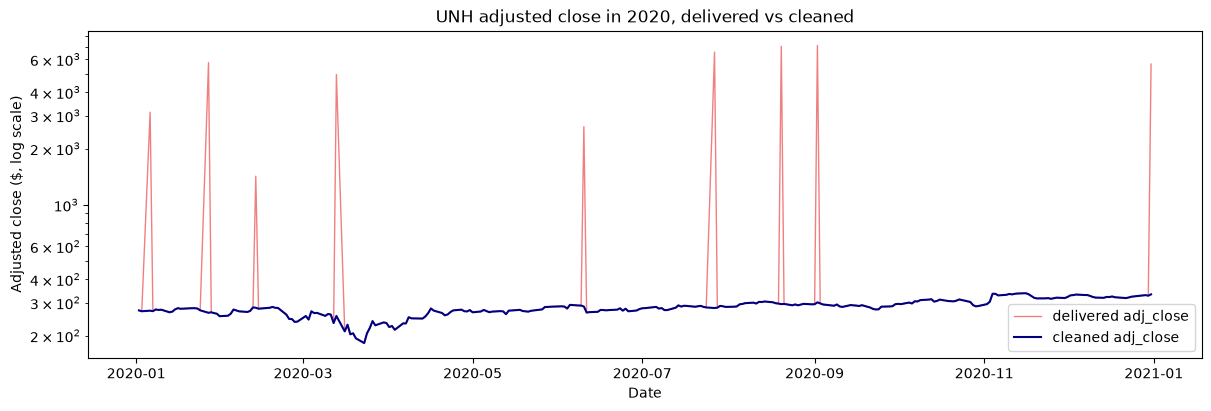

In [30]:
example = 'UNH'
window = ('2020-01-01', '2020-12-31')
before = data[(data['ticker'] == example) & data['ts'].between(*window)].drop_duplicates(VALUE_COLS)
after = cleaned[(cleaned['ticker'] == example) & cleaned['ts'].between(*window)]
fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
ax.plot(pd.to_datetime(before['ts']), before['adj_close'], color='lightcoral', lw=1, label='delivered adj_close')
ax.plot(pd.to_datetime(after['ts']), after['adj_close'], color='navy', lw=1.5, label='cleaned adj_close')
ax.set(yscale='log', title=f'{example} adjusted close in 2020, delivered vs cleaned',
       xlabel='Date', ylabel='Adjusted close ($, log scale)')
ax.legend()
plt.show()

### Save

In [31]:
with closing(sqlite3.connect(DB_PATH)) as conn:
    cleaned.to_sql('ohlc_hw_cleaned', conn, if_exists='replace', index=False)
    conn.execute('CREATE UNIQUE INDEX IF NOT EXISTS ix_ohlc_hw_cleaned_ticker_ts ON ohlc_hw_cleaned (ticker, ts)')
    quarantine.to_sql('ohlc_hw_quarantine', conn, if_exists='replace', index=False)
    ticker_audit.to_sql('ohlc_hw_ticker_audit', conn, if_exists='replace', index=False)
    quality_report.to_sql('ohlc_hw_quality_report', conn, if_exists='replace', index=False)
    conn.commit()

    saved = pd.read_sql_query('SELECT * FROM ohlc_hw_cleaned', conn)
    raw_rows_now = conn.execute('SELECT COUNT(*) FROM ohlc_hw').fetchone()[0]
    aapl_2024 = conn.execute("SELECT COUNT(*) FROM ohlc_hw_cleaned "
                             "WHERE ticker = 'AAPL' AND ts BETWEEN '2024-01-01' AND '2024-12-31'").fetchone()[0]

assert raw_rows_now == RAW_ROWS, 'raw table changed'
assert len(saved) == len(cleaned) and validate_clean(saved)['passed'].all()
print(f'ohlc_hw_cleaned: {len(saved):,} rows, {saved["ticker"].nunique()} tickers, {saved["ts"].min()} to {saved["ts"].max()}')
print(f'ohlc_hw_quarantine: {len(quarantine)} rows, ohlc_hw untouched: {raw_rows_now:,} rows')
print('date filter check, AAPL rows in 2024:', aapl_2024)

ohlc_hw_cleaned: 367,862 rows, 30 tickers, 1962-01-02 to 2024-12-06
ohlc_hw_quarantine: 389 rows, ohlc_hw untouched: 397,711 rows
date filter check, AAPL rows in 2024: 202
